# Optimasi Rute Wisata Semarang Menggunakan ABC dan Random Keys

**Swarm Intelligence, Pertemuan 10: Representasi Solusi dan Adaptasi Algoritma Swarm**

Purna Siswantomo, C2C023160. Dua anggota lain dan pembagian pekerjaan aktual perlu dilengkapi kelompok.

Kasus: perencanaan urutan kunjungan terhadap lokasi nyata di Semarang. Ini eksperimen
komputasional dengan data publik, bukan catatan perjalanan wisatawan atau penerapan operasional.
Lawang Sewu menjadi titik awal dan akhir, sepuluh destinasi lain dikunjungi tepat sekali.
Tujuan minimisasi total estimasi waktu berkendara. Jam buka, lama kunjungan, kemacetan
aktual, biaya tiket dan kelayakan selesai dalam sehari belum dimodelkan.

Lokasi: Nominatim/OpenStreetMap; matriks jalan: OSRM driving. Semua respons mentah
dan sumber per lokasi ada dalam folder data. © OpenStreetMap contributors, ODbL 1.0.
Lihat https://www.openstreetmap.org/copyright dan https://project-osrm.org/docs/v26.4.0/http.
Titik POI belum diverifikasi sebagai pintu masuk pengunjung; snapping ke jalan adalah pendekatan.

Jalankan notebook dari folder project. Data sudah disimpan sehingga eksperimen tidak
memerlukan internet. Pengunduhan ulang opsional memakai src/download_data.py.


In [1]:
from pathlib import Path
import json, time, itertools, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BASE=Path.cwd()
assert (BASE/'data'/'locations.csv').exists(), 'Jalankan dari folder Project ABC Wisata Semarang'
OUT=BASE/'hasil';OUT.mkdir(exist_ok=True)
locations=pd.read_csv(BASE/'data'/'locations.csv')
T=pd.read_csv(BASE/'data'/'durations.csv').to_numpy(float)
DIST=pd.read_csv(BASE/'data'/'distances.csv').to_numpy(float)
assert T.shape==(len(locations),len(locations))
assert np.isfinite(T).all() and (T>=0).all() and np.allclose(np.diag(T),0)
display(locations[['id','name','latitude','longitude','osm_url']])
display(pd.DataFrame(T/60,index=locations.name,columns=locations.name).round(2))
print('Matriks asimetris:',not np.allclose(T,T.T))
print('Data provenance:',json.loads((BASE/'data'/'provenance.json').read_text(encoding='utf-8')))


,id,name,latitude,longitude,osm_url
0,0,Lawang Sewu,-6.983979,110.410791,https://www.openstreetmap.org/way/439246632
1,1,Sam Poo Kong,-6.995872,110.398384,https://www.openstreetmap.org/way/572968702
2,2,Gereja Blenduk,-6.968163,110.427463,https://www.openstreetmap.org/way/1418750680
3,3,Pantai Marina,-6.947666,110.390141,https://www.openstreetmap.org/way/1428417764
4,4,Museum Ranggawarsita,-6.986037,110.383947,https://www.openstreetmap.org/way/558671846
5,5,Grand Maerakaca,-6.960640,110.385894,https://www.openstreetmap.org/way/573517271
6,6,Masjid Agung Jawa Tengah,-6.983646,110.445592,https://www.openstreetmap.org/way/573529590
7,7,Kampung Pelangi,-6.987787,110.408491,https://www.openstreetmap.org/node/5025494121
8,8,Tugu Muda,-6.984323,110.409333,https://www.openstreetmap.org/node/257882831
9,9,Vihara Buddhagaya Watugong,-7.086439,110.409595,https://www.openstreetmap.org/way/476128960


name,Lawang Sewu,Sam Poo Kong,Gereja Blenduk,Pantai Marina,Museum Ranggawarsita,Grand Maerakaca,Masjid Agung Jawa Tengah,Kampung Pelangi,Tugu Muda,Vihara Buddhagaya Watugong,Taman Indonesia Kaya
name,,,,,,,,,,,
Lawang Sewu,0.00,3.37,4.65,10.06,3.80,9.17,7.10,0.85,0.54,13.66,2.22
Sam Poo Kong,3.43,0.00,6.82,9.15,2.89,8.26,9.42,2.31,3.09,13.50,3.47
Gereja Blenduk,4.18,6.67,0.00,10.45,7.10,9.55,6.48,4.15,3.84,15.46,4.89
Pantai Marina,9.84,9.05,10.32,0.00,6.93,7.75,14.29,9.76,9.50,20.95,10.92
Museum Ranggawarsita,4.03,3.18,6.99,7.04,0.00,6.14,10.25,3.89,3.69,15.08,5.05
Grand Maerakaca,9.15,8.36,10.51,7.22,6.24,0.00,14.49,9.06,8.80,20.26,10.23
Masjid Agung Jawa Tengah,7.19,9.29,6.27,14.39,9.73,13.50,0.00,6.77,6.85,15.19,6.32
Kampung Pelangi,1.13,2.52,4.52,9.93,3.66,9.04,7.35,0.00,0.79,12.81,2.78
Tugu Muda,0.72,3.22,4.11,9.52,3.26,8.63,6.94,0.70,0.00,13.50,2.06


Matriks asimetris: True
Data provenance: {'retrieved_utc': '2026-11-19T23:49:19.755830+00:00', 'locations_source': 'Nominatim / OpenStreetMap', 'osm_attribution': '© OpenStreetMap contributors, ODbL 1.0', 'osm_license': 'https://www.openstreetmap.org/copyright', 'matrix_url': 'https://router.project-osrm.org/table/v1/driving/110.4107909,-6.9839786;110.3983842,-6.9958722;110.4274633,-6.9681633;110.3901407,-6.9476655;110.3839468,-6.9860374;110.3858937,-6.9606397;110.4455923,-6.9836458;110.4084912,-6.9877873;110.4093328,-6.9843233;110.4095947,-7.0864388;110.4200237,-6.992088?annotations=duration%2Cdistance', 'matrix_source': 'OSRM driving table', 'objective_unit': 'seconds', 'distance_unit': 'meters', 'live_traffic': False, 'location_selection': 'Name-matched POI in Semarang bounding box, excluding highway/boundary; raw candidates saved. Watugong is Vihara Buddhagaya POI, not the residential road returned first.', 'note': 'Locations are mapped POI reference points, not verified visitor en

## Representasi solusi, search space dan objective

Satu food source adalah vektor 10 random keys dalam [0,1], bukan satu objek wisata.
Stable argsort menghasilkan urutan ID destinasi 1..10; ID 0 ditempatkan tetap di awal
dan akhir. Search space vektor kontinu [0,1]^10 dipetakan ke 10! = 3.628.800 permutasi.
Banyak vektor berbeda dapat menghasilkan rute yang sama, sehingga ada plateau representasi.

Contoh empat tujuan: keys [0,72; 0,18; 0,91; 0,43] menghasilkan urutan [2,4,1,3].
Angka key bukan koordinat atau biaya perjalanan. Tie diselesaikan stabil menurut ID.
Constraint tepat satu kunjungan dijamin decoder, bukan penalti. Keys di luar rentang
di-clip. Sisi yang tidak dapat dirutekan akan ditolak saat validasi data, bukan diberi
nilai nol atau diganti jarak garis lurus.

Objective f(pi) = T[0,pi1] + sum T[pi_i,pi_(i+1)] + T[pi_n,0], dalam detik.
Karena matriks jalan bisa asimetris, rute terbalik belum tentu mempunyai biaya sama.
Fitness untuk seleksi probabilistik adalah 1/(1+f), lalu dinormalisasi menjadi peluang.
Ini bukan perbandingan jarak lurus maupun optimasi durasi berwisata keseluruhan.


In [2]:
"""Random-key ABC for a fixed-depot directed tour. No route-specific shortcuts."""
import numpy as np
from time import perf_counter

def decode(keys):
    return np.r_[0, np.argsort(keys, kind='stable')+1, 0].astype(int)

def tour_cost(route, matrix):
    return float(matrix[route[:-1],route[1:]].sum())

def validate_route(route, n):
    assert len(route)==n+1 and route[0]==route[-1]==0
    assert sorted(route[1:-1])==list(range(1,n))

def solve(matrix, seed=11, method='ABC', budget=5000, sources=20, limit=50):
    assert method in ('ABC','Random') and budget>=sources and sources>=2
    start=perf_counter()
    rng=np.random.default_rng(seed); dim=len(matrix)-1
    pop=rng.random((sources,dim)); trials=np.zeros(sources,int)
    costs=np.array([tour_cost(decode(x),matrix) for x in pop])
    used=sources; bestidx=int(costs.argmin()); bestkey=pop[bestidx].copy();best=float(costs[bestidx])
    history_fe=[used];history_best=[best]; unique_population=[len({tuple(decode(x)) for x in pop})]
    all_routes={tuple(decode(x)) for x in pop}; same_route=0; scouts=0; candidates=0; neighbor_attempts=0
    def evaluate(v):
        nonlocal used,best,bestkey,candidates
        route=decode(v);validate_route(route,len(matrix))
        score=tour_cost(route,matrix);used+=1;candidates+=1;all_routes.add(tuple(route))
        if score<best:best=score;bestkey=v.copy()
        return score
    def neighbor(i):
        nonlocal same_route, neighbor_attempts
        neighbor_attempts+=1
        k=int(rng.integers(sources-1));k+=k>=i
        j=int(rng.integers(dim));v=pop[i].copy()
        v[j]=np.clip(v[j]+rng.uniform(-1,1)*(v[j]-pop[k,j]),0,1)
        same_route+=int(np.array_equal(decode(v),decode(pop[i])))
        score=evaluate(v)
        if score<costs[i]: pop[i]=v;costs[i]=score;trials[i]=0
        else:trials[i]+=1
    while used<budget:
        if method=='Random':
            # Same first 20 candidates as ABC, then independent random keys.
            v=rng.random(dim);evaluate(v)
            if used%40==0 or used==budget:
                history_fe.append(used);history_best.append(best)
                unique_population.append(None)
            continue
        for i in range(sources):
            if used==budget:break
            neighbor(i)
        # Static roulette probabilities per onlooker phase, as in classical ABC.
        fitness=1/(1+costs);prob=fitness/fitness.sum()
        for _ in range(sources):
            if used==budget:break
            neighbor(int(rng.choice(sources,p=prob)))
        if used<budget and trials.max()>=limit:
            i=int(trials.argmax());pop[i]=rng.random(dim);costs[i]=evaluate(pop[i]);trials[i]=0;scouts+=1
        history_fe.append(used);history_best.append(best)
        unique_population.append(len({tuple(decode(x)) for x in pop}))
    route=decode(bestkey);validate_route(route,len(matrix))
    assert used==budget and np.isclose(tour_cost(route,matrix),best)
    assert np.all(np.diff(history_best)<=1e-9)
    return {'method':method,'seed':seed,'cost_seconds':best,'runtime_seconds':perf_counter()-start,
            'evaluations':used,'route':route.tolist(),'keys':bestkey.tolist(),'unique_routes':len(all_routes),
            'same_route_fraction':same_route/max(1,neighbor_attempts) if method=='ABC' else None,
            'scouts':scouts,'history_fe':history_fe,'history_best':history_best,
            'unique_population':unique_population}

def nearest_neighbor(matrix):
    pending=set(range(1,len(matrix)));route=[0]
    while pending:
        nxt=min(pending,key=lambda j:(matrix[route[-1],j],j));route.append(nxt);pending.remove(nxt)
    route.append(0);return route,tour_cost(np.array(route),matrix)

def held_karp(matrix):
    """Exact dynamic programming for a small directed fixed-depot TSP."""
    m=len(matrix)-1;dp={};parent={}
    for j in range(m):dp[(1<<j,j)]=float(matrix[0,j+1])
    for mask in range(1,1<<m):
        for j in range(m):
            if not(mask>>j&1) or mask==(1<<j):continue
            prev=mask^(1<<j)
            cost,k=min((dp[(prev,k)]+matrix[k+1,j+1],k) for k in range(m) if prev>>k&1)
            dp[(mask,j)]=float(cost);parent[(mask,j)]=k
    mask=(1<<m)-1
    value,j=min((dp[(mask,j)]+matrix[j+1,0],j) for j in range(m))
    rev=[]
    while True:
        rev.append(j+1)
        if mask==1<<j:break
        k=parent[(mask,j)];mask^=1<<j;j=k
    route=[0]+rev[::-1]+[0];validate_route(route,len(matrix))
    assert np.isclose(tour_cost(np.array(route),matrix),value)
    return route,float(value)


In [3]:
demo=np.array([.72,.18,.91,.43])
print('Keys:',demo,'Rute:',decode(demo))
assert decode(demo).tolist()==[0,2,4,1,3,0]
assert decode(np.ones(4)).tolist()==[0,1,2,3,4,0]
# Uji oracle eksak terhadap enumerasi pada matriks kecil yang asimetris.
check=np.random.default_rng(91).integers(1,200,size=(6,6)).astype(float)
np.fill_diagonal(check,0)
small_route,small_value=held_karp(check)
brute=min(tour_cost(np.array((0,)+p+(0,)),check) for p in itertools.permutations(range(1,6)))
assert np.isclose(small_value,brute)
print('Decoder, tie handling, dan Held-Karp lulus pemeriksaan.')


Keys: [0.72 0.18 0.91 0.43] Rute: [0 2 4 1 3 0]
Decoder, tie handling, dan Held-Karp lulus pemeriksaan.


## Adaptasi fase ABC

Employed bee memilih peer k berbeda dari i dan satu dimensi j, lalu menghitung
v_ij = x_ij + phi_ij(x_ij - x_kj), phi uniform [-1,1]. Kandidat di-clip dan di-decode,
kemudian diterima hanya bila objective membaik ketat. Trial bertambah bila gagal,
termasuk ketika keys berubah tetapi rutenya sama.

Onlooker memilih sumber makanan menurut peluang fitness, lalu memakai operator yang
sama. Probabilitas dibekukan per fase onlooker. Scout mengganti satu sumber dengan
trial tertinggi jika mencapai limit; arsip best-so-far tetap disimpan.

Gerak kontinu tetap dipertahankan. Adaptasi utamanya berada pada decoder dan evaluasi
permutasi. Ini tidak diklaim sebagai algoritma baru atau varian improved.


## Desain eksperimen

ABC: 20 food sources, 20 percobaan onlooker per siklus, limit 50.
Berhenti tepat pada 5.000 evaluasi, termasuk 20 evaluasi populasi awal dan evaluasi scout.
Seed 11,22,...,220 (20 run). Random search memakai 20 kandidat awal yang sama per seed,
lalu kandidat independen hingga anggaran yang sama. Setiap panggilan objective tetap
dihitung meskipun menghasilkan rute duplikat; tidak ada cache tersembunyi.

Nearest neighbor memakai depot yang sama. Held-Karp menjadi referensi eksak bagi
instance kecil ini, bukan baseline dengan anggaran sama. Keduanya deterministik,
sehingga tidak dibuat 20 hasil semu atau standard deviation antar-run palsu.
Konfigurasi ini pilihan awal yang transparan, bukan hasil tuning optimal.


In [4]:
SEEDS=list(range(11,221,11)); BUDGET=5000
start=time.perf_counter();exact_route,exact_value=held_karp(T);exact_time=time.perf_counter()-start
start=time.perf_counter();nn_route,nn_value=nearest_neighbor(T);nn_time=time.perf_counter()-start
runs=[]
for seed in SEEDS:
    # Rotate order to reduce systematic runtime ordering effects.
    for method in (['ABC','Random'] if seed//11%2 else ['Random','ABC']):
        r=solve(T,seed=seed,method=method,budget=BUDGET,sources=20,limit=50)
        assert r['cost_seconds']>=exact_value-1e-7
        runs.append(r)
df=pd.DataFrame([{k:v for k,v in r.items() if k not in ('history_fe','history_best','unique_population','keys')} for r in runs])
df['minutes']=df.cost_seconds/60
df['gap_percent']=100*(df.cost_seconds-exact_value)/exact_value
summary=df.groupby('method').agg(best_minutes=('minutes','min'),mean_minutes=('minutes','mean'),
    std_minutes=('minutes','std'),worst_minutes=('minutes','max'),mean_gap_percent=('gap_percent','mean'),
    mean_runtime_s=('runtime_seconds','mean'),mean_unique_routes=('unique_routes','mean'),
    optimum_hits=('gap_percent',lambda x:int(np.isclose(x,0,atol=1e-7).sum()))).reset_index()
display(summary)
print('Nearest neighbor:',nn_value/60,'menit; exact:',exact_value/60,'menit')
print('NN gap:',100*(nn_value-exact_value)/exact_value,'%')
df.to_csv(OUT/'runs_20_seed.csv',index=False);summary.to_csv(OUT/'summary.csv',index=False)
with (OUT/'histories.json').open('w') as f:json.dump(runs,f,indent=2,allow_nan=False)
best=min((r for r in runs if r['method']=='ABC'),key=lambda r:r['cost_seconds'])
route=best['route'];validate_route(route,len(T))
legs=pd.DataFrame([{'from':locations.name.iloc[a],'to':locations.name.iloc[b],
    'minutes':T[a,b]/60,'km':DIST[a,b]/1000} for a,b in zip(route[:-1],route[1:])])
display(legs);legs.to_csv(OUT/'best_route_legs.csv',index=False)
print('Rute terbaik:', ' -> '.join(locations.name.iloc[i] for i in route))
assert np.isclose(legs.minutes.sum()*60,best['cost_seconds'])
report={'exact_seconds':exact_value,'exact_route':exact_route,'exact_runtime_s':exact_time,
        'nn_seconds':nn_value,'nn_route':nn_route,'nn_runtime_s':nn_time,
        'best_abc_seconds':best['cost_seconds'],'best_abc_route':route,'best_abc_seed':best['seed'],
        'nodes':len(T),'destinations':len(T)-1,'budget':BUDGET,'seeds':SEEDS,
        'data_sha256':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in (BASE/'data').glob('*.csv')}}
(OUT/'report.json').write_text(json.dumps(report,indent=2))


,method,best_minutes,mean_minutes,std_minutes,worst_minutes,mean_gap_percent,mean_runtime_s,mean_unique_routes,optimum_hits
0,ABC,70.510,71.528750,0.664597,72.601667,1.444831,0.315647,1981.9,4
1,Random,72.215,74.085333,0.966576,75.433333,5.070676,0.081277,4996.2,0


,from,to,minutes,km
0,Lawang Sewu,Kampung Pelangi,0.848333,0.5363
1,Kampung Pelangi,Sam Poo Kong,2.520000,2.0783
2,Sam Poo Kong,Museum Ranggawarsita,2.888333,2.6365
3,Museum Ranggawarsita,Grand Maerakaca,6.145000,4.3548
4,Grand Maerakaca,Pantai Marina,7.220000,2.8878
5,Pantai Marina,Gereja Blenduk,10.316667,7.8370
6,Gereja Blenduk,Masjid Agung Jawa Tengah,6.476667,4.3126
7,Masjid Agung Jawa Tengah,Vihara Buddhagaya Watugong,15.193333,14.0274
8,Vihara Buddhagaya Watugong,Taman Indonesia Kaya,15.548333,12.6168
9,Taman Indonesia Kaya,Tugu Muda,2.630000,2.4883


Nearest neighbor: 81.21833333333333 menit; exact: 70.50999999999999 menit
NN gap: 15.186971115208268 %
Rute terbaik: Lawang Sewu -> Kampung Pelangi -> Sam Poo Kong -> Museum Ranggawarsita -> Grand Maerakaca -> Pantai Marina -> Gereja Blenduk -> Masjid Agung Jawa Tengah -> Vihara Buddhagaya Watugong -> Taman Indonesia Kaya -> Tugu Muda -> Lawang Sewu


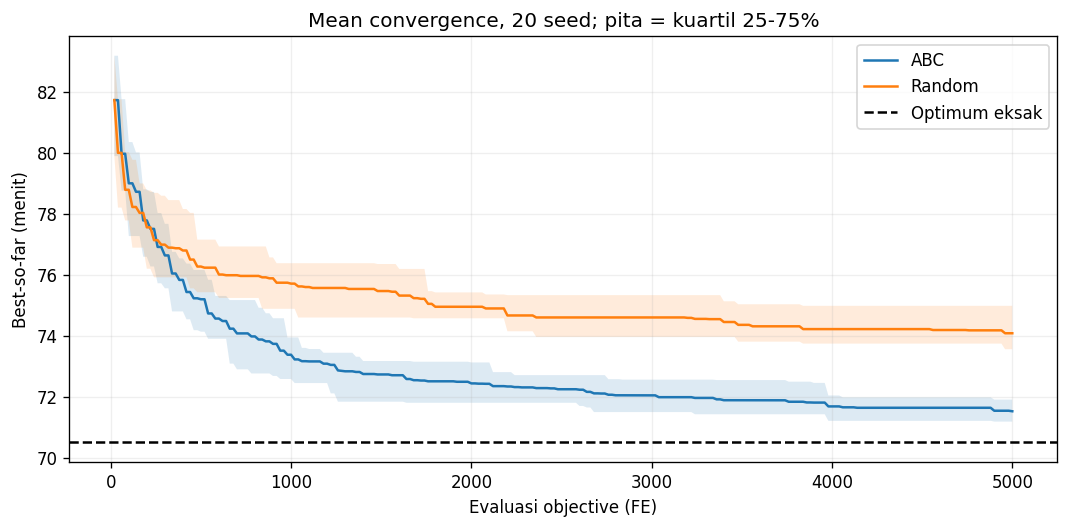

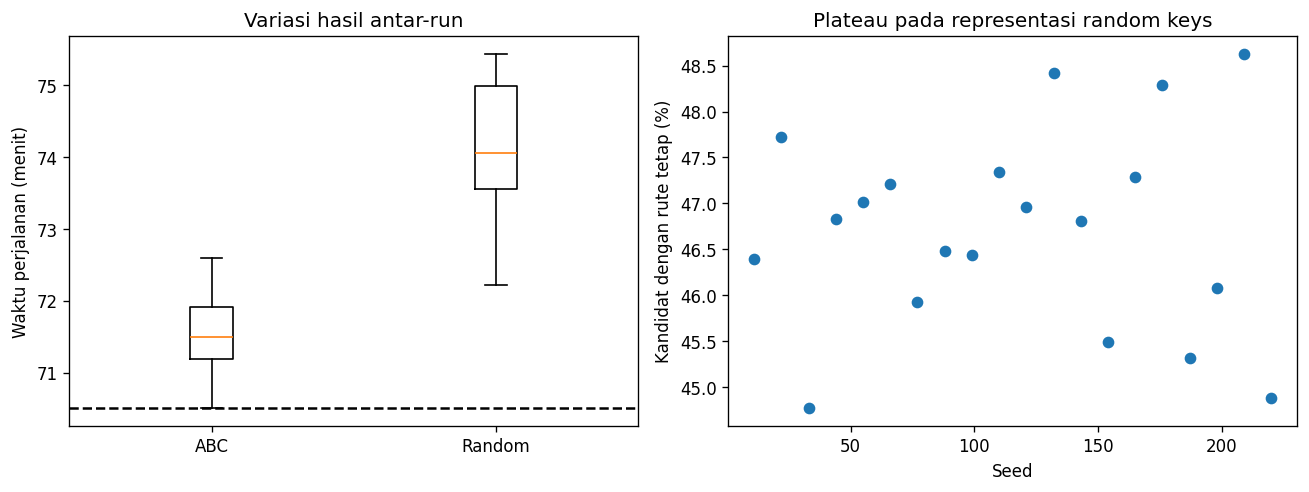

In [5]:
grid=np.arange(20,BUDGET+1,20)
fig,ax=plt.subplots(figsize=(9,4.5))
for method in ['ABC','Random']:
    curves=[]
    for r in runs:
        if r['method']!=method:continue
        idx=np.searchsorted(r['history_fe'],grid,side='right')-1
        curves.append(np.array(r['history_best'])[idx]/60)
    curves=np.array(curves)
    ax.plot(grid,curves.mean(axis=0),label=method)
    ax.fill_between(grid,np.quantile(curves,.25,axis=0),np.quantile(curves,.75,axis=0),alpha=.15)
ax.axhline(exact_value/60,color='black',ls='--',label='Optimum eksak')
ax.set(xlabel='Evaluasi objective (FE)',ylabel='Best-so-far (menit)',title='Mean convergence, 20 seed; pita = kuartil 25-75%')
ax.legend();ax.grid(alpha=.2);fig.tight_layout();fig.savefig(OUT/'convergence.png',dpi=160);plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4.2))
axes[0].boxplot([df[df.method==m].minutes for m in ['ABC','Random']],tick_labels=['ABC','Random'])
axes[0].axhline(exact_value/60,c='black',ls='--');axes[0].set(ylabel='Waktu perjalanan (menit)',title='Variasi hasil antar-run')
abcrows=df[df.method=='ABC']
axes[1].scatter(abcrows.seed,abcrows.same_route_fraction*100)
axes[1].set(xlabel='Seed',ylabel='Kandidat dengan rute tetap (%)',title='Plateau pada representasi random keys')
fig.tight_layout();fig.savefig(OUT/'stability_encoding.png',dpi=160);plt.show()


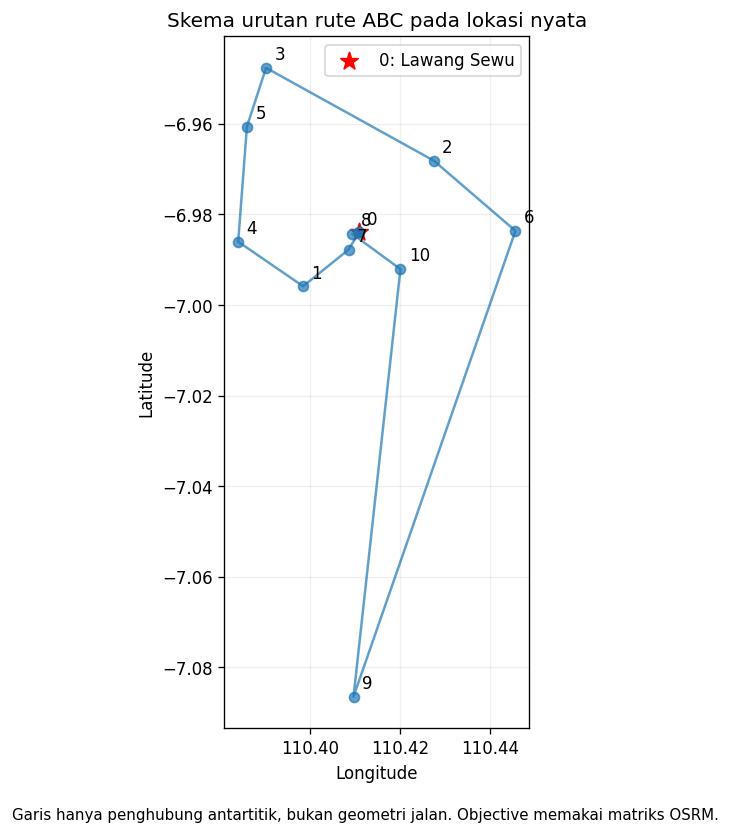

,id,name
0,0,Lawang Sewu
1,1,Sam Poo Kong
2,2,Gereja Blenduk
3,3,Pantai Marina
4,4,Museum Ranggawarsita
5,5,Grand Maerakaca
6,6,Masjid Agung Jawa Tengah
7,7,Kampung Pelangi
8,8,Tugu Muda
9,9,Vihara Buddhagaya Watugong


In [6]:
fig,ax=plt.subplots(figsize=(8,7))
xy=locations[['longitude','latitude']].to_numpy()
ax.plot(xy[route,0],xy[route,1],'-o',alpha=.7)
for i,(x,y) in enumerate(xy):ax.annotate(str(i),(x,y),xytext=(5,5),textcoords='offset points')
ax.scatter(xy[0,0],xy[0,1],c='red',s=120,marker='*',label='0: Lawang Sewu')
ax.set(xlabel='Longitude',ylabel='Latitude',title='Skema urutan rute ABC pada lokasi nyata')
ax.set_aspect(1/np.cos(np.deg2rad(locations.latitude.mean())))
ax.grid(alpha=.2);ax.legend()
fig.text(.12,.015,'Garis hanya penghubung antartitik, bukan geometri jalan. Objective memakai matriks OSRM.',fontsize=9)
fig.tight_layout(rect=(0,.04,1,1));fig.savefig(OUT/'route_schematic.png',dpi=160);plt.show()
display(locations[['id','name']])


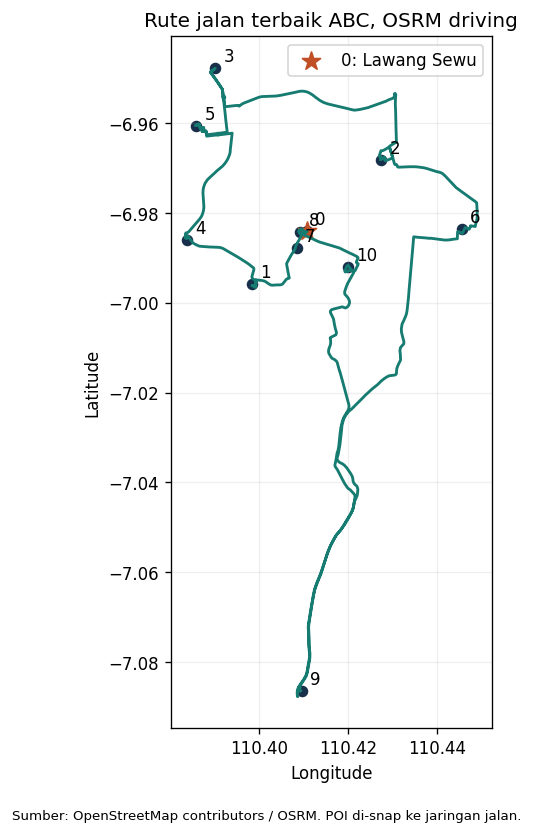

In [7]:

# Geometri jalan sebenarnya dari OSRM; tetap bukan observasi lalu lintas aktual.
road=json.loads((BASE/'data'/'best_route_osrm.json').read_text())['routes'][0]
assert np.isclose(road['duration'],best['cost_seconds'],atol=.11)
roadxy=np.array(road['geometry']['coordinates'])
fig,ax=plt.subplots(figsize=(7,7))
ax.plot(roadxy[:,0],roadxy[:,1],lw=1.7,c='#167b70')
ax.scatter(locations.longitude,locations.latitude,c='#172f4a',s=35)
for i,row in locations.iterrows():ax.annotate(str(i),(row.longitude,row.latitude),xytext=(5,4),textcoords='offset points')
ax.scatter(locations.longitude.iloc[0],locations.latitude.iloc[0],c='#c04f25',s=130,marker='*',label='0: Lawang Sewu')
ax.set(xlabel='Longitude',ylabel='Latitude',title='Rute jalan terbaik ABC, OSRM driving')
ax.set_aspect(1/np.cos(np.deg2rad(locations.latitude.mean())));ax.grid(alpha=.2);ax.legend()
fig.text(.12,.015,'Sumber: OpenStreetMap contributors / OSRM. POI di-snap ke jaringan jalan.',fontsize=8)
fig.tight_layout(rect=(0,.04,1,1));fig.savefig(OUT/'route_roads.png',dpi=170);plt.show()


## Interpretasi dan keterbatasan

Lihat tabel dan grafik hasil di atas. Analisis harus membedakan best satu run, mean,
std, gap terhadap optimum dan runtime komputasi dari waktu perjalanan rute.
Random keys menghindari tujuan hilang/ganda, tetapi perubahan satu key sering
tidak menyeberangi key lain, sehingga rute tidak berubah. Persentase kandidat dengan
rute tetap mengukur masalah ini langsung, bukan hanya menduga dari kurva datar.

Scout mendukung exploration, sedangkan seleksi onlooker dan greedy acceptance
mendukung exploitation. Mencapai optimum pada salah satu seed tidak menjamin semua
run mencapainya. Solusi eksak layak untuk 10 destinasi dan menjadi pemeriksa mutu;
ABC ditunjukkan sebagai metode adaptasi dan dapat diuji lagi pada instance lebih besar.

Hasil hanya optimal terhadap matriks statis yang disimpan. Jam buka, durasi kunjungan,
akses kendaraan ke pintu masuk dan lalu lintas aktual belum diverifikasi.
Peta garis antartitik adalah skema urutan, bukan petunjuk navigasi.

Pembagian peran yang diusulkan: anggota 1 memeriksa sumber lokasi dan formulasi,
anggota 2 menjelaskan implementasi ABC/decoder, anggota 3 memeriksa evaluasi dan visualisasi.
Nama dan kontribusi aktual diisi sesuai pekerjaan kelompok; semua anggota perlu menguasai seluruh alur.


## Hasil dan kesimpulan dari eksekusi

ABC menghasilkan mean **71.5287 menit**, std sampel **0.6646 menit**,
best **70.5100 menit** dan worst **72.6017 menit**.
Random search: mean **74.0853 menit** dan std **0.9666 menit**.
Pada anggaran 5.000 evaluasi yang sama, mean ABC lebih rendah
**3.45%** dari random search.
Nearest neighbor menghasilkan **81.2183 menit**.

Optimum Held-Karp untuk matriks ini **70.5100 menit**.
ABC mencapai nilai tersebut pada **4/20 run**, random search pada
**0/20 run**. Mean optimality gap ABC **1.445%**.
Mencapai optimum pada run terbaik tidak sama dengan selalu mencapai optimum.

Rata-rata **46.72%** kandidat tetangga ABC memiliki urutan yang sama dengan
sumbernya meskipun nilai key berubah atau terpotong di batas. Ini bukti langsung plateau
decoder. Random search menjelajah lebih banyak rute unik, tetapi tidak menggunakan
seleksi terarah sehingga mean kualitasnya lebih buruk pada anggaran ini.

Runtime mean ABC **0.3156 detik** dan random **0.0813 detik**.
Held-Karp selesai dalam **0.0133 detik** pada perangkat pengujian ini.
Jadi untuk hanya 10 destinasi, metode eksak justru praktis dan memberi kepastian optimum.
ABC digunakan untuk mempelajari adaptasi kontinu-ke-permutasi; keunggulan pada instance
lebih besar perlu diuji lagi dan tidak boleh diklaim dari eksperimen ini.

Tidak dilakukan uji signifikansi, sehingga perbedaan yang dilaporkan adalah deskriptif.
Data jaringan jalan statis dan aturan berhenti di tiap POI, tanpa kemacetan aktual.
Geometri rute diambil dengan continue_straight=false agar perhentian dapat berbalik
sesuai matriks antartitik. Durasi route service cocok dengan penjumlahan matriks.


Tabel gabungan ABC, random search, nearest neighbor dan exact tersedia di `hasil/comparison_all_methods.csv`. Kolom mean/std dibiarkan kosong untuk metode deterministik satu hasil.
